design a software app that is able to process a fasta file of a genome either from a virus or a bacteria. find the frequencies of the codons over the genome and plot and show into the console the top 10 most frequent codons. use the AI in order to formulate a prompt in which the frequencies are shown to the AI and in which the AI is asked about a list of foods that contain the least amount of the aminoacids associated with the codons found in the top 10 list detected by it.

note: use a sliding window with 3 positions in order to measure the frequency of the codons.


In [1]:
# 1. read the FASTA file and count codons with a sliding window of 3 (step 1)
from collections import Counter

FASTA_FILE = "ecoli_cft073.fasta"


def read_fasta(path):
    header, seq = None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                header = line[1:]
            elif line:
                seq.append(line.upper())
    return header, "".join(seq)


def codon_frequencies(seq, window=3):
    counts = Counter()
    for i in range(len(seq) - window + 1):
        codon = seq[i:i + window]
        if set(codon) <= set("ACGT"):  # skip windows with N or other ambiguous bases
            counts[codon] += 1
    return counts


header, genome = read_fasta(FASTA_FILE)
counts = codon_frequencies(genome)
total = sum(counts.values())
print(header)
print(f"genome length: {len(genome)} bp, windows counted: {total}, distinct codons: {len(counts)}")

NC_004431.1 Escherichia coli CFT073, complete sequence
genome length: 5231428 bp, windows counted: 5230612, distinct codons: 64


rank codon       count   freq %  amino acid
1    TTT        124180    2.374  Phenylalanine
2    AAA        124136    2.373  Lysine
3    CGC        124032    2.371  Arginine
4    GCG        123313    2.358  Alanine
5    CAG        120155    2.297  Glutamine
6    CTG        118042    2.257  Leucine
7    GCA        107812    2.061  Alanine
8    TGC        106710    2.040  Cysteine
9    GCC        102758    1.965  Alanine
10   GGC        101907    1.948  Glycine


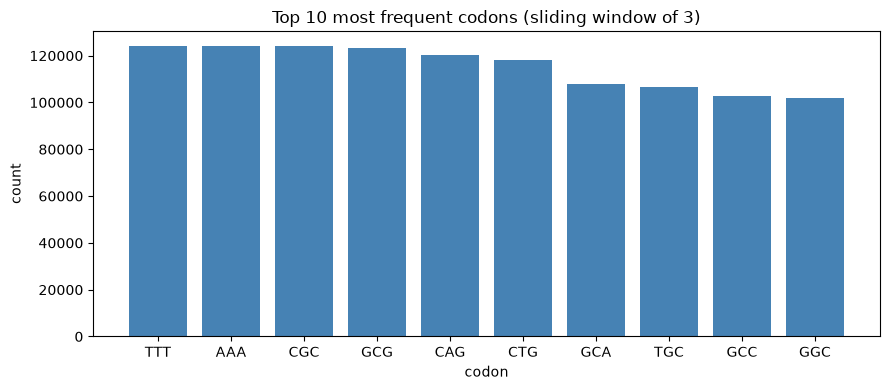

In [2]:
# 2. top 10 codons: print in console + plot
import matplotlib.pyplot as plt

CODON_TABLE = {
    "TTT": "Phenylalanine", "TTC": "Phenylalanine", "TTA": "Leucine", "TTG": "Leucine",
    "CTT": "Leucine", "CTC": "Leucine", "CTA": "Leucine", "CTG": "Leucine",
    "ATT": "Isoleucine", "ATC": "Isoleucine", "ATA": "Isoleucine", "ATG": "Methionine",
    "GTT": "Valine", "GTC": "Valine", "GTA": "Valine", "GTG": "Valine",
    "TCT": "Serine", "TCC": "Serine", "TCA": "Serine", "TCG": "Serine",
    "CCT": "Proline", "CCC": "Proline", "CCA": "Proline", "CCG": "Proline",
    "ACT": "Threonine", "ACC": "Threonine", "ACA": "Threonine", "ACG": "Threonine",
    "GCT": "Alanine", "GCC": "Alanine", "GCA": "Alanine", "GCG": "Alanine",
    "TAT": "Tyrosine", "TAC": "Tyrosine", "TAA": "Stop", "TAG": "Stop",
    "CAT": "Histidine", "CAC": "Histidine", "CAA": "Glutamine", "CAG": "Glutamine",
    "AAT": "Asparagine", "AAC": "Asparagine", "AAA": "Lysine", "AAG": "Lysine",
    "GAT": "Aspartic acid", "GAC": "Aspartic acid", "GAA": "Glutamic acid", "GAG": "Glutamic acid",
    "TGT": "Cysteine", "TGC": "Cysteine", "TGA": "Stop", "TGG": "Tryptophan",
    "CGT": "Arginine", "CGC": "Arginine", "CGA": "Arginine", "CGG": "Arginine",
    "AGT": "Serine", "AGC": "Serine", "AGA": "Arginine", "AGG": "Arginine",
    "GGT": "Glycine", "GGC": "Glycine", "GGA": "Glycine", "GGG": "Glycine",
}

top10 = counts.most_common(10)

print(f"{'rank':<5}{'codon':<7}{'count':>10}{'freq %':>9}  amino acid")
for rank, (codon, n) in enumerate(top10, 1):
    print(f"{rank:<5}{codon:<7}{n:>10}{100 * n / total:>9.3f}  {CODON_TABLE[codon]}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([c for c, _ in top10], [n for _, n in top10], color="steelblue")
ax.set_xlabel("codon")
ax.set_ylabel("count")
ax.set_title("Top 10 most frequent codons (sliding window of 3)")
plt.tight_layout()
plt.show()

## Foods lowest in the amino acids of the top 10 codons

Amino acids from the top 10 codons: Alanine, Arginine, Cysteine, Glutamine, Glycine, Leucine, Lysine, Phenylalanine.

Almost all protein-containing foods have some of each of these amino acids, so the foods with the least of them are the ones with almost no protein at all.

**Practically none of these amino acids**
- Oils and fats: olive oil, sunflower oil, coconut oil, lard (butter has a trace)
- Sugars and syrups: table sugar, honey, maple syrup, agave
- Pure starches: tapioca, cornstarch, arrowroot, sago

**Very low (under ~1 g protein per 100 g)**
- Fruits: watermelon, apple, pear, grapes, peach, pineapple, orange, strawberries
- Watery vegetables: cucumber, lettuce, celery, zucchini, radish, cabbage
- Low-protein roots: cassava (the root itself), sweet potato, potato (~2 g per 100 g, so low rather than near zero)

**Low-ish, with caveats**
- Rice, corn and wheat products: low in lysine in particular, but they still have a fair amount of leucine, arginine and alanine
- Fruit juices, jams and jellies

**Foods to avoid for this goal**
- Meat, fish, eggs and dairy: high in all eight
- Legumes, soy, nuts and seeds: very high in arginine, leucine and lysine
- Gelatin and collagen products: very high in glycine and alanine

**Caveats**
- This is a rough nutritional ranking, not medical advice.
- The bacterium's most frequent codons say nothing about what a person should eat. This is an exercise in connecting a genome to a prompt.